# Name: Prathamesh Balaji Patil
# Roll: 11
# Div: TY A(AIML)
#Experiment No.9

# Experiment No. 09 — Implementation of Linear SVM

## Counterfeit Banknote Detection using Linear SVM

### Problem Statement
Develop a Linear Support Vector Machine (SVM) classification model that learns a separating hyperplane from labelled banknote samples and deploy it as a web application using Flask and HTML.

### Objective
Use the Banknote Authentication dataset to predict whether a banknote is **genuine or counterfeit** from four numerical features extracted from its image:

- Variance
- Skewness
- Curtosis
- Entropy

**Algorithm:** Linear Support Vector Machine (SVM)  
**Dataset:** `data_banknote_authentication.csv`


## 1. Import Libraries

Import the libraries required for data handling, visualization, model training, and evaluation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Banknote Authentication Dataset from Google Drive

Upload `data_banknote_authentication.csv` to the top level of **My Drive**. If you store it in a folder, update `file_path` accordingly.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = "/content/drive/MyDrive/Colab Notebooks/data_banknote_authentication.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## 3. Inspect the Dataset

The dataset contains four input features and one target column named `class`. In the commonly used dataset encoding, class `0` represents genuine banknotes and class `1` represents counterfeit banknotes.

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

print("\nTotal records:", len(df))

Column names:
['variance', 'skewness', 'curtosis', 'entropy', 'class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Total records: 1372


## 4. Visualize the Class Distribution

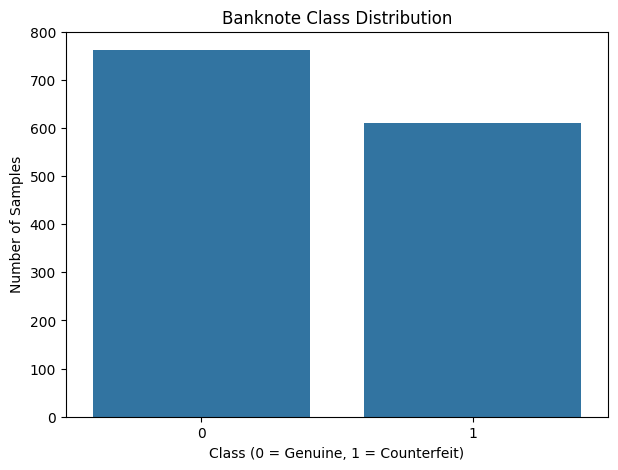

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="class")
plt.title("Banknote Class Distribution")
plt.xlabel("Class (0 = Genuine, 1 = Counterfeit)")
plt.ylabel("Number of Samples")
plt.show()

## 5. Prepare Features and Target

`X` contains the four numerical measurements. `y` contains the class label to predict.

In [ ]:
feature_columns = ["variance", "skewness", "curtosis", "entropy"]

X = df[feature_columns]
y = df["class"].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(feature_columns)

Feature shape: (1372, 4)
Target shape: (1372,)

Features:
['variance', 'skewness', 'curtosis', 'entropy']


## 6. Split the Dataset

Use 75% of the records for training and 25% for testing. `stratify=y` preserves the class proportions in both sets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1029
Testing samples: 343


## 7. Feature Scaling and Linear SVM

SVM is sensitive to feature scales, so use `StandardScaler`. A pipeline ensures scaling is fitted only on training data and applies the same transformation during prediction.

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])

model.fit(X_train, y_train)

print("Linear SVM model trained successfully!")

Linear SVM model trained successfully!


## 8. Make Predictions

In [ ]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Class": y_test.to_numpy(),
    "Predicted Class": y_pred
})

display(results.head(10))

,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,0,0
6,1,1
7,1,1
8,1,1
9,1,1


## 9. Evaluate the Model

Accuracy measures the percentage of correct predictions. The classification report includes precision, recall, and F1-score for each class.

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Genuine (0)", "Counterfeit (1)"]
))

Accuracy: 97.67%

Classification Report:
                 precision    recall  f1-score   support

    Genuine (0)       1.00      0.96      0.98       191
Counterfeit (1)       0.95      1.00      0.97       152

       accuracy                           0.98       343
      macro avg       0.97      0.98      0.98       343
   weighted avg       0.98      0.98      0.98       343



## 10. Confusion Matrix

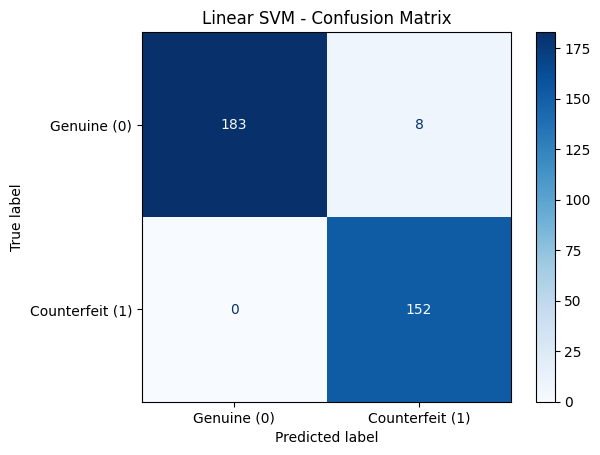

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine (0)", "Counterfeit (1)"]
)
disp.plot(cmap="Blues")
plt.title("Linear SVM - Confusion Matrix")
plt.show()

## 11. Predict a New Banknote Sample

Enter four numerical feature values in this order: variance, skewness, curtosis, entropy. The example values below are only an example input; replace them with values you want to test.

In [ ]:
# Example feature values: variance, skewness, curtosis, entropy
sample = pd.DataFrame(
    [[3.6216, 8.6661, -2.8073, -0.44699]],
    columns=feature_columns
)

prediction = int(model.predict(sample)[0])

if prediction == 0:
    print("Prediction: Genuine banknote")
else:
    print("Prediction: Counterfeit banknote")

print("Predicted class:", prediction)

Prediction: Genuine banknote
Predicted class: 0


## 12. Save the Trained Model

The saved pipeline includes both the scaler and the Linear SVM classifier. The Flask application can load this single file to make predictions.

In [ ]:
joblib.dump(model, "linear_svm_banknote_model.pkl")
print("Saved: linear_svm_banknote_model.pkl")

Saved: linear_svm_banknote_model.pkl


## 13. Download the Trained Model

Run this cell to download the model file to your computer. Place it in the same folder as your Flask application when you build the web interface.

In [ ]:
from google.colab import files
files.download("linear_svm_banknote_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Result

A Linear SVM classifier was trained on the Banknote Authentication dataset to distinguish genuine and counterfeit banknotes using variance, skewness, curtosis, and entropy. The model was evaluated using accuracy, a classification report, and a confusion matrix, and the trained pipeline was saved for Flask integration.

# HTML Code:

In [ ]:
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Banknote Authentication | Linear SVM</title>
    <style>
        :root {
            --navy: #152744;
            --blue: #2855a6;
            --bg: #f3f6fb;
            --text: #1e293b;
            --muted: #64748b;
            --border: #dbe3ef;
        }
        * { box-sizing: border-box; }
        body {
            margin: 0;
            font-family: Arial, Helvetica, sans-serif;
            color: var(--text);
            background: linear-gradient(135deg, #edf3ff, var(--bg));
            min-height: 100vh;
            padding: 32px 16px;
        }
        .container { max-width: 760px; margin: 0 auto; }
        header { text-align: center; margin-bottom: 24px; }
        .badge {
            display: inline-block;
            padding: 7px 12px;
            border-radius: 999px;
            color: var(--blue);
            background: #e1eaff;
            font-size: 12px;
            font-weight: 700;
            letter-spacing: .5px;
            text-transform: uppercase;
        }
        h1 { color: var(--navy); margin: 14px 0 8px; font-size: clamp(26px, 4vw, 36px); }
        header p { color: var(--muted); margin: 0; line-height: 1.5; }
        .card {
            background: #fff;
            border: 1px solid var(--border);
            border-radius: 18px;
            padding: clamp(20px, 4vw, 32px);
            box-shadow: 0 14px 40px rgba(21, 39, 68, .08);
        }
        .card h2 { margin: 0 0 8px; color: var(--navy); font-size: 21px; }
        .hint { margin: 0 0 22px; color: var(--muted); font-size: 14px; line-height: 1.5; }
        .grid { display: grid; grid-template-columns: repeat(2, minmax(0, 1fr)); gap: 18px; }
        label { display: block; font-size: 14px; font-weight: 700; margin-bottom: 8px; }
        input {
            width: 100%;
            padding: 13px 12px;
            border: 1px solid #cbd5e1;
            border-radius: 9px;
            font-size: 15px;
            color: var(--text);
            outline: none;
        }
        input:focus { border-color: var(--blue); box-shadow: 0 0 0 3px rgba(40, 85, 166, .12); }
        .actions { display: flex; gap: 12px; margin-top: 24px; }
        button, .secondary {
            border: 0; border-radius: 9px; padding: 13px 18px;
            font-weight: 700; font-size: 15px; cursor: pointer; text-align: center;
        }
        button { flex: 1; color: white; background: var(--blue); }
        button:hover { background: #1f4387; }
        .secondary { color: var(--navy); background: #eef2f8; text-decoration: none; }
        .result, .error { margin-top: 22px; padding: 18px; border-radius: 12px; }
        .result h3 { margin: 0 0 7px; font-size: 20px; }
        .result p, .error p { margin: 0; line-height: 1.5; }
        .genuine { background: #eaf8ef; border: 1px solid #b9e7c8; color: #166534; }
        .counterfeit { background: #fff0f0; border: 1px solid #f3c0c0; color: #991b1b; }
        .error { background: #fff7ed; border: 1px solid #fed7aa; color: #9a3412; }
        .note { margin-top: 20px; color: var(--muted); font-size: 12px; line-height: 1.5; text-align: center; }
        footer { text-align: center; margin-top: 20px; color: var(--muted); font-size: 13px; }
        @media (max-width: 560px) {
            .grid { grid-template-columns: 1fr; }
            .actions { flex-direction: column; }
        }
    </style>
</head>
<body>
    <main class="container">
        <header>
            <span class="badge">Machine Learning Practical · Experiment 09</span>
            <h1>Banknote Authentication</h1>
            <p>Predict whether a banknote sample is genuine or counterfeit using your trained Linear SVM model.</p>
        </header>

        <section class="card">
            <h2>Enter the four features</h2>
            <p class="hint">Enter numeric values extracted from the banknote image. The feature names and order match the Colab notebook.</p>

            <form method="POST" action="/">
                <div class="grid">
                    <div>
                        <label for="variance">Variance</label>
                        <input id="variance" name="variance" type="number" step="any" required value="{{ values.variance }}" placeholder="e.g. 3.6216">
                    </div>
                    <div>
                        <label for="skewness">Skewness</label>
                        <input id="skewness" name="skewness" type="number" step="any" required value="{{ values.skewness }}" placeholder="e.g. 8.6661">
                    </div>
                    <div>
                        <label for="curtosis">Curtosis</label>
                        <input id="curtosis" name="curtosis" type="number" step="any" required value="{{ values.curtosis }}" placeholder="e.g. -2.8073">
                    </div>
                    <div>
                        <label for="entropy">Entropy</label>
                        <input id="entropy" name="entropy" type="number" step="any" required value="{{ values.entropy }}" placeholder="e.g. -0.44699">
                    </div>
                </div>
                <div class="actions">
                    <button type="submit">Predict Banknote</button>
                    <a class="secondary" href="/">Reset</a>
                </div>
            </form>

            {% if prediction %}
            <div class="result {{ prediction.kind }}" role="status">
                <h3>{{ prediction.label }}</h3>
                <p>{{ prediction.description }}</p>
                <p><strong>Predicted class:</strong> {{ prediction['class'] }}</p>
            </div>
            {% endif %}

            {% if error %}
            <div class="error" role="alert"><p>{{ error }}</p></div>
            {% endif %}
        </section>

        <p class="note">Dataset label mapping used in the notebook: class 0 = Genuine, class 1 = Counterfeit.</p>
        <footer>Built with Flask, HTML, Pandas and a trained scikit-learn Linear SVM pipeline.</footer>
    </main>
</body>
</html>


# Flask Code:

In [ ]:
from pathlib import Path

import joblib
import pandas as pd
from flask import Flask, render_template, request

app = Flask(__name__)

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "linear_svm_banknote_model.pkl"

# This is the trained Pipeline from the Colab notebook. It includes
# StandardScaler and the Linear SVM classifier.
model = joblib.load(MODEL_PATH)

FEATURES = ["variance", "skewness", "curtosis", "entropy"]


@app.route("/", methods=["GET", "POST"])
def index():
    prediction = None
    error = None
    values = {feature: "" for feature in FEATURES}

    if request.method == "POST":
        try:
            row = {}
            for feature in FEATURES:
                raw_value = request.form.get(feature, "").strip()
                values[feature] = raw_value
                if not raw_value:
                    raise ValueError(f"Please enter a value for {feature.title()}.")
                row[feature] = float(raw_value)

            # Keep the same feature names and order used to train the model.
            input_data = pd.DataFrame([row], columns=FEATURES)
            predicted_class = int(model.predict(input_data)[0])

            if predicted_class == 0:
                prediction = {
                    "label": "Genuine Banknote",
                    "class": 0,
                    "description": "The trained Linear SVM model classified this sample as genuine.",
                    "kind": "genuine",
                }
            else:
                prediction = {
                    "label": "Counterfeit Banknote",
                    "class": 1,
                    "description": "The trained Linear SVM model classified this sample as counterfeit.",
                    "kind": "counterfeit",
                }

        except ValueError as exc:
            error = str(exc) if str(exc).startswith("Please enter") else (
                "Please enter valid numeric values in all four fields."
            )
        except Exception:
            app.logger.exception("Prediction failed")
            error = "Prediction could not be completed. Check that the model file and dependencies are correct."

    return render_template("index.html", prediction=prediction, error=error, values=values)


if __name__ == "__main__":
    # Run locally for the practical. Debug mode is enabled for development only.
    app.run(debug=True)
